In [ ]:
!pip install nltk pandas matplotlib

In [ ]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
from collections import Counter

In [ ]:
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
text = """
Wildlife conservation protects endangered animals.
Forest guardians are planting trees in damaged areas.
Elephants migrate across large grasslands.
Environmental scientists study animal behavior carefully.
National parks provide safe habitats for rare species.
"""

print(text)


Wildlife conservation protects endangered animals.
Forest guardians are planting trees in damaged areas.
Elephants migrate across large grasslands.
Environmental scientists study animal behavior carefully.
National parks provide safe habitats for rare species.



In [ ]:
tokens = word_tokenize(text)

print("Tokens:")
print(tokens)

Tokens:
['Wildlife', 'conservation', 'protects', 'endangered', 'animals', '.', 'Forest', 'guardians', 'are', 'planting', 'trees', 'in', 'damaged', 'areas', '.', 'Elephants', 'migrate', 'across', 'large', 'grasslands', '.', 'Environmental', 'scientists', 'study', 'animal', 'behavior', 'carefully', '.', 'National', 'parks', 'provide', 'safe', 'habitats', 'for', 'rare', 'species', '.']


In [ ]:
stemmer = PorterStemmer()

stems = []

for word in tokens:
    stems.append(stemmer.stem(word))

print("Stemmed Words:")
print(stems)

Stemmed Words:
['wildlif', 'conserv', 'protect', 'endang', 'anim', '.', 'forest', 'guardian', 'are', 'plant', 'tree', 'in', 'damag', 'area', '.', 'eleph', 'migrat', 'across', 'larg', 'grassland', '.', 'environment', 'scientist', 'studi', 'anim', 'behavior', 'care', '.', 'nation', 'park', 'provid', 'safe', 'habitat', 'for', 'rare', 'speci', '.']


In [ ]:
lemmatizer = WordNetLemmatizer()

lemmas = []

for word in tokens:
    lemmas.append(lemmatizer.lemmatize(word.lower()))

print("Lemmatized Words:")
print(lemmas)

Lemmatized Words:
['wildlife', 'conservation', 'protects', 'endangered', 'animal', '.', 'forest', 'guardian', 'are', 'planting', 'tree', 'in', 'damaged', 'area', '.', 'elephant', 'migrate', 'across', 'large', 'grassland', '.', 'environmental', 'scientist', 'study', 'animal', 'behavior', 'carefully', '.', 'national', 'park', 'provide', 'safe', 'habitat', 'for', 'rare', 'specie', '.']


In [ ]:
pos_tags = nltk.pos_tag(tokens)

print("POS Tags:")
print(pos_tags)

POS Tags:
[('Wildlife', 'NNP'), ('conservation', 'NN'), ('protects', 'NNS'), ('endangered', 'VBN'), ('animals', 'NNS'), ('.', '.'), ('Forest', 'JJS'), ('guardians', 'NNS'), ('are', 'VBP'), ('planting', 'VBG'), ('trees', 'NNS'), ('in', 'IN'), ('damaged', 'VBN'), ('areas', 'NNS'), ('.', '.'), ('Elephants', 'NNS'), ('migrate', 'VBP'), ('across', 'IN'), ('large', 'JJ'), ('grasslands', 'NNS'), ('.', '.'), ('Environmental', 'JJ'), ('scientists', 'NNS'), ('study', 'VBP'), ('animal', 'JJ'), ('behavior', 'NN'), ('carefully', 'RB'), ('.', '.'), ('National', 'NNP'), ('parks', 'NNS'), ('provide', 'VBP'), ('safe', 'JJ'), ('habitats', 'NNS'), ('for', 'IN'), ('rare', 'JJ'), ('species', 'NNS'), ('.', '.')]


In [ ]:
analysis = []

for word in tokens:
    analysis.append([
        word,
        stemmer.stem(word),
        lemmatizer.lemmatize(word.lower())
    ])

df = pd.DataFrame(
    analysis,
    columns=["Word", "Stem", "Lemma"]
)

display(df)

,Word,Stem,Lemma
0,Wildlife,wildlif,wildlife
1,conservation,conserv,conservation
2,protects,protect,protects
3,endangered,endang,endangered
4,animals,anim,animal
5,.,.,.
6,Forest,forest,forest
7,guardians,guardian,guardian
8,are,are,are
9,planting,plant,planting


In [ ]:
pos_df = pd.DataFrame(
    pos_tags,
    columns=["Word", "POS Tag"]
)

display(pos_df)

,Word,POS Tag
0,Wildlife,NNP
1,conservation,NN
2,protects,NNS
3,endangered,VBN
4,animals,NNS
5,.,.
6,Forest,JJS
7,guardians,NNS
8,are,VBP
9,planting,VBG


In [ ]:
grammar = "NP: {<DT>?<JJ.*>*<NN.*>+}"

chunk_parser = nltk.RegexpParser(grammar)

chunk_tree = chunk_parser.parse(pos_tags)

print("Noun Phrase Chunks:")
print(chunk_tree)

Noun Phrase Chunks:
(S
  (NP Wildlife/NNP conservation/NN protects/NNS)
  endangered/VBN
  (NP animals/NNS)
  ./.
  (NP Forest/JJS guardians/NNS)
  are/VBP
  planting/VBG
  (NP trees/NNS)
  in/IN
  damaged/VBN
  (NP areas/NNS)
  ./.
  (NP Elephants/NNS)
  migrate/VBP
  across/IN
  (NP large/JJ grasslands/NNS)
  ./.
  (NP Environmental/JJ scientists/NNS)
  study/VBP
  (NP animal/JJ behavior/NN)
  carefully/RB
  ./.
  (NP National/NNP parks/NNS)
  provide/VBP
  (NP safe/JJ habitats/NNS)
  for/IN
  (NP rare/JJ species/NNS)
  ./.)


In [ ]:
tag_frequency = Counter(tag for word, tag in pos_tags)

tag_df = pd.DataFrame(
    tag_frequency.items(),
    columns=["POS Tag", "Frequency"]
)

tag_df = tag_df.sort_values(
    by="Frequency",
    ascending=False
)

display(tag_df)

,POS Tag,Frequency
2,NNS,11
9,JJ,5
4,.,5
6,VBP,4
8,IN,3
1,NN,2
0,NNP,2
3,VBN,2
5,JJS,1
7,VBG,1


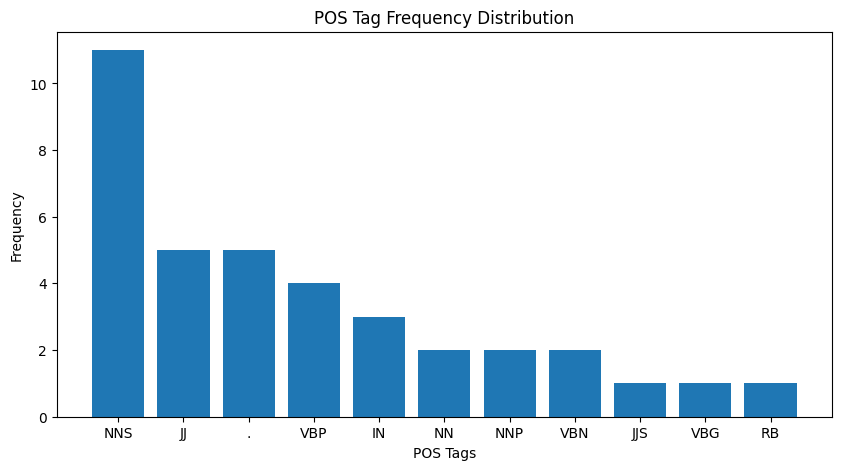

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(tag_df["POS Tag"], tag_df["Frequency"])

plt.title("POS Tag Frequency Distribution")
plt.xlabel("POS Tags")
plt.ylabel("Frequency")

plt.show()

In [ ]:
final_analysis = []

for word, pos in pos_tags:

    final_analysis.append([
        word,
        stemmer.stem(word),
        lemmatizer.lemmatize(word.lower()),
        pos
    ])

final_df = pd.DataFrame(
    final_analysis,
    columns=["Word", "Stem", "Lemma", "POS Tag"]
)

display(final_df)

,Word,Stem,Lemma,POS Tag
0,Wildlife,wildlif,wildlife,NNP
1,conservation,conserv,conservation,NN
2,protects,protect,protects,NNS
3,endangered,endang,endangered,VBN
4,animals,anim,animal,NNS
5,.,.,.,.
6,Forest,forest,forest,JJS
7,guardians,guardian,guardian,NNS
8,are,are,are,VBP
9,planting,plant,planting,VBG
